In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from lightgbm import LGBMRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

1. SETUP TRAINING DATA AND FEATURES ENGINEERING

In [3]:
# Load and Sort Data
df = pd.read_csv("../dataset/preprocessed_data_unscaled.csv")
df['Date'] = pd.to_datetime(df['Date'])
df = df.sort_values('Date').reset_index(drop=True)

target = 'PM25'
pollutants = ['CO', 'Ozone', 'PM10', 'NO2']

In [4]:
# Feature Engineering
# create lag features
lags_pm25 = [1,2,7]
for lag in lags_pm25:
    df[f'PM25_lag{lag}'] = df[target].shift(lag)
for pollutant in pollutants:
    for lag in lags_pm25:
        df[f'{pollutant}_lag{lag}'] = df[pollutant].shift(lag)

In [5]:
# rolling window statistics
windows = [7,14]
for window in windows:
    df[f'PM25_roll_mean_{window}'] = df[target].rolling(window).mean().shift(1)
    df[f'PM25_roll_std_{window}'] = df[target].rolling(window).std().shift(1)
    for pollutant in pollutants:
        df[f'{pollutant}_roll_mean_{window}'] = df[pollutant].rolling(window).mean().shift(1)

In [6]:
# cycling encoding on the time variables
df['TimeIndex'] = np.arange(len(df))
df['Year'] = df['Date'].dt.year
df['Month'] = df['Date'].dt.month
df['DayOfYear'] = df['Date'].dt.dayofyear
df['DayOfWeek'] = df['Date'].dt.dayofweek
df['IsWeekend'] = (df['DayOfWeek'] >= 5).astype(int)
df['DayOfYear_sin'] = np.sin(2*np.pi*df['DayOfYear']/365)
df['DayOfYear_cos'] = np.cos(2*np.pi*df['DayOfYear']/365)
df['Month_sin'] = np.sin(2*np.pi*df['Month']/12)
df['Month_cos'] = np.cos(2*np.pi*df['Month']/12)

In [7]:
epsilon = 1e-6
df['PM10_PM25_ratio'] = (df['PM10']/(df['PM25']+epsilon)).clip(0.1,10)
df['PM25_roc_1'] = df['PM25'].pct_change(1).fillna(0).clip(-0.5,0.5)

df = df.dropna().reset_index(drop=True)

In [8]:
# Define Features
feature_cols = [
    'CO','Ozone','PM10','NO2','TimeIndex','Month','DayOfWeek','IsWeekend',
    'DayOfYear_sin','DayOfYear_cos','Month_sin','Month_cos',
    'PM25_lag1','PM25_lag2','PM25_lag7',
    'CO_lag1','Ozone_lag1','PM10_lag1',
    'PM25_roll_mean_7','PM25_roll_std_7','PM25_roll_mean_14',
    'PM10_PM25_ratio','PM25_roc_1'
]

In [9]:
# Split Data
test_size = int(0.2*len(df))
X = df[feature_cols]
y = df[target]
X_train = X.iloc[:-test_size]
X_test = X.iloc[-test_size:]
y_train = y.iloc[:-test_size]
y_test = y.iloc[-test_size:]

2. SETUP, TRAIN AND FIT MODEL

In [10]:
# Define Model
params = {
    'n_estimators': 300, 'learning_rate': 0.05, 'max_depth': 6,
    'num_leaves': 31, 'subsample': 0.8, 'colsample_bytree': 0.8,
    'reg_alpha': 0.2, 'reg_lambda': 0.2, 'min_child_samples': 20,
    'min_split_gain': 0.01, 'random_state': 42
}
model = LGBMRegressor(**params)

In [11]:
print("Training LGBM Model...")
model.fit(X_train, y_train)
y_test_pred = model.predict(X_test)

Training LGBM Model...
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.000246 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 2717
[LightGBM] [Info] Number of data points in the train set: 1451, number of used features: 23
[LightGBM] [Info] Start training from score 48.983460
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further spl

3. MODEL PERFORMANCE

In [12]:
r2 = r2_score(y_test, y_test_pred)
mse = mean_squared_error(y_test, y_test_pred)
rmse = np.sqrt(mse)
mae = mean_absolute_error(y_test, y_test_pred)
mape = np.mean(np.abs((y_test - y_test_pred) / (np.abs(y_test)+1e-6))) * 100

print("\n===== LGBM MODEL PERFORMANCE (Test Set) =====")
print(f"R²: {r2:.4f}")
print(f"MSE: {mse:.4f}")
print(f"RMSE: {rmse:.4f}")
print(f"MAE: {mae:.4f}")
print(f"MAPE: {mape:.2f}%")


===== LGBM MODEL PERFORMANCE (Test Set) =====
R²: 0.8904
MSE: 50.4897
RMSE: 7.1056
MAE: 2.8072
MAPE: 8.06%


4. SCATTER PLOT (Actual vs Predicted)

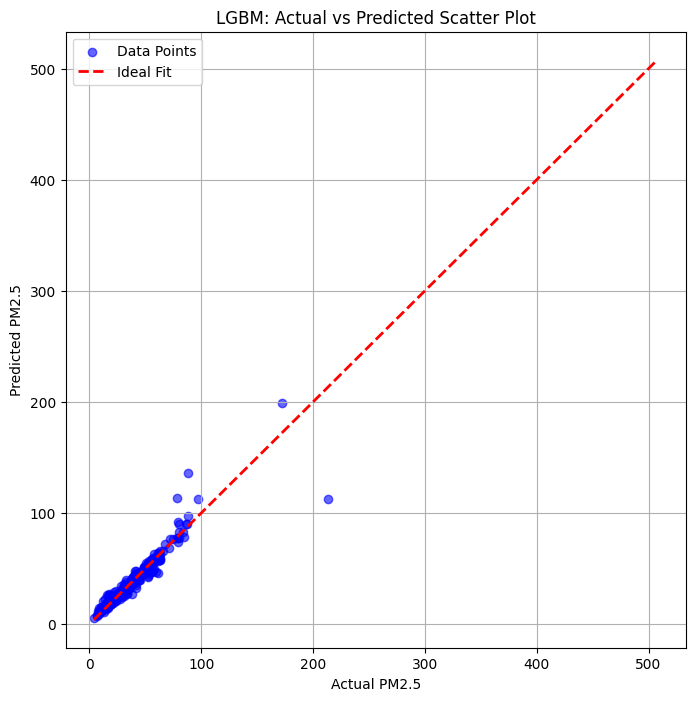

In [13]:
plt.figure(figsize=(8, 8))
plt.scatter(y_test, y_test_pred, alpha=0.6, color='blue', label='Data Points')
plt.plot([y.min(), y.max()], [y.min(), y.max()], 'r--', lw=2, label='Ideal Fit')
plt.xlabel("Actual PM2.5")
plt.ylabel("Predicted PM2.5")
plt.title("LGBM: Actual vs Predicted Scatter Plot")
plt.legend()
plt.grid(True)
plt.show()

5. TIME SERIES PLOT (Actual vs Predicted)

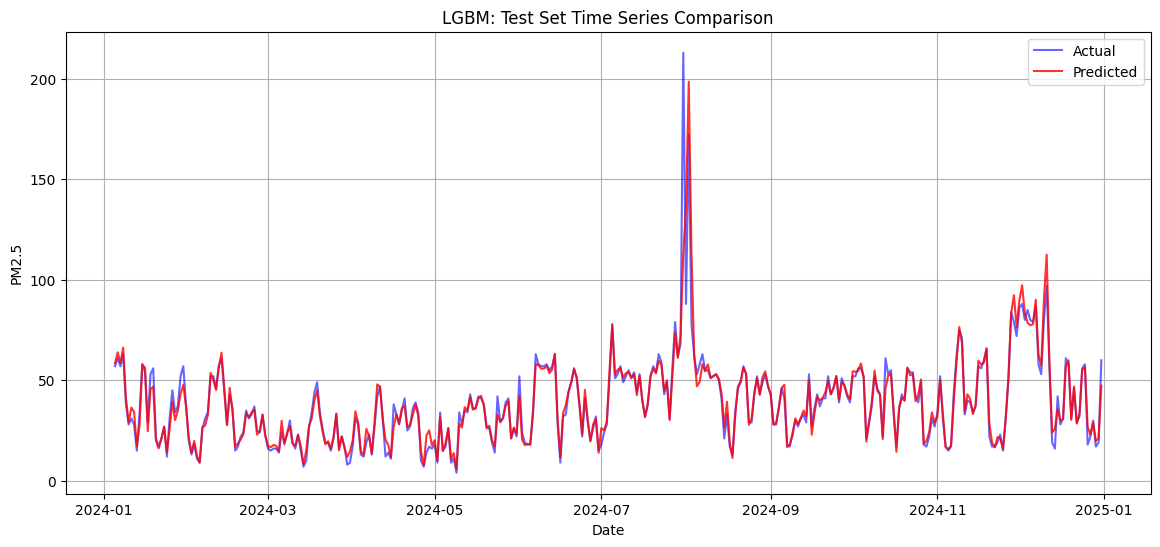

In [14]:
plt.figure(figsize=(14, 6))
plt.plot(df['Date'].iloc[-test_size:], y_test, label='Actual', color='blue', alpha=0.6)
plt.plot(df['Date'].iloc[-test_size:], y_test_pred, label='Predicted', color='red', alpha=0.8)
plt.xlabel("Date")
plt.ylabel("PM2.5")
plt.title("LGBM: Test Set Time Series Comparison")
plt.legend()
plt.grid(True)
plt.show()

6. FORECAST 5 YEARS

In [15]:
forecast_days = 365 * 5
last_row = df.iloc[-1].copy()

# Prepare structures
future_dates = []
future_preds = []
future_uncertainty = []

# Historical rolling/pollutant buffers
recent_pm25 = list(df['PM25'].iloc[-14:])
recent_pollutants = {p:list(df[p].iloc[-7:]) for p in pollutants}

rng = np.random.default_rng(42)

# Seasonal patterns
seasonal_patterns = {}
for month in range(1,13):
    month_data = df[df['Month']==month]
    seasonal_patterns[month] = {p+'_mean':month_data[p].mean() for p in ['PM25']+pollutants}

for day in range(forecast_days):
    current_date = last_row['Date'] + pd.Timedelta(days=day+1)
    
    # Time features
    last_row['TimeIndex'] += 1
    last_row['Month'] = current_date.month
    last_row['DayOfWeek'] = current_date.dayofweek
    last_row['IsWeekend'] = 1 if current_date.dayofweek>=5 else 0
    day_of_year = current_date.timetuple().tm_yday
    last_row['DayOfYear_sin1'] = np.sin(2*np.pi*day_of_year/365)
    last_row['DayOfYear_cos1'] = np.cos(2*np.pi*day_of_year/365)
    last_row['Month_sin1'] = np.sin(2*np.pi*current_date.month/12)
    last_row['Month_cos1'] = np.cos(2*np.pi*current_date.month/12)
    
    # Pollutant seasonal drift
    for p in ['CO','Ozone','PM10','NO2']:
        drift = 0.1
        noise = 0.02
        seasonal_mean = seasonal_patterns[current_date.month][p+'_mean']
        last_row[p] = last_row[p]*(1-drift) + seasonal_mean*drift + rng.normal(0,noise)
        if len(recent_pollutants[p])>=7: recent_pollutants[p].pop(0)
        recent_pollutants[p].append(last_row[p])
    
    # Update PM25 lags
    for lag in [7,2,1]:
        lag_col = f'PM25_lag{lag}'
        if lag_col in feature_cols:
            if lag==1:
                last_row[lag_col] = future_preds[-1] if future_preds else last_row[lag_col]
            elif lag==2:
                last_row[lag_col] = future_preds[-2] if len(future_preds)>=2 else last_row[lag_col]
            elif lag==7:
                last_row[lag_col] = future_preds[-7] if len(future_preds)>=7 else last_row[lag_col]
    
    # Rolling features
    recent_pm25.append(future_preds[-1] if future_preds else last_row['PM25'])
    if len(recent_pm25)>14: recent_pm25.pop(0)
    last_row['PM25_roll_mean_7'] = np.mean(recent_pm25[-7:])
    last_row['PM25_roll_std_7'] = np.std(recent_pm25[-7:])
    last_row['PM25_roll_mean_14'] = np.mean(recent_pm25[-14:])
    
    # Interaction
    last_row['PM10_PM25_ratio'] = (last_row['PM10']/(recent_pm25[-1]+1e-6)).clip(0.1,10)
    last_row['PM25_roc_1'] = ((recent_pm25[-1]-recent_pm25[-2])/(recent_pm25[-2]+1e-6)).clip(-0.5,0.5) if len(recent_pm25)>1 else 0
    
    # Prepare feature vector
    X_next = pd.DataFrame([last_row[feature_cols].values],columns=feature_cols)
    
    # Predict
    pm25_pred = model.predict(X_next)[0]
    uncertainty = rmse*0.5
    
    future_dates.append(current_date)
    future_preds.append(pm25_pred)
    future_uncertainty.append(uncertainty)

# Forecast DataFrame
forecast_df = pd.DataFrame({
    'Date': future_dates,
    'Forecast_PM25': future_preds,
    'Uncertainty': future_uncertainty,
    'Lower_Bound': np.array(future_preds)-1.96*np.array(future_uncertainty),
    'Upper_Bound': np.array(future_preds)+1.96*np.array(future_uncertainty)
})

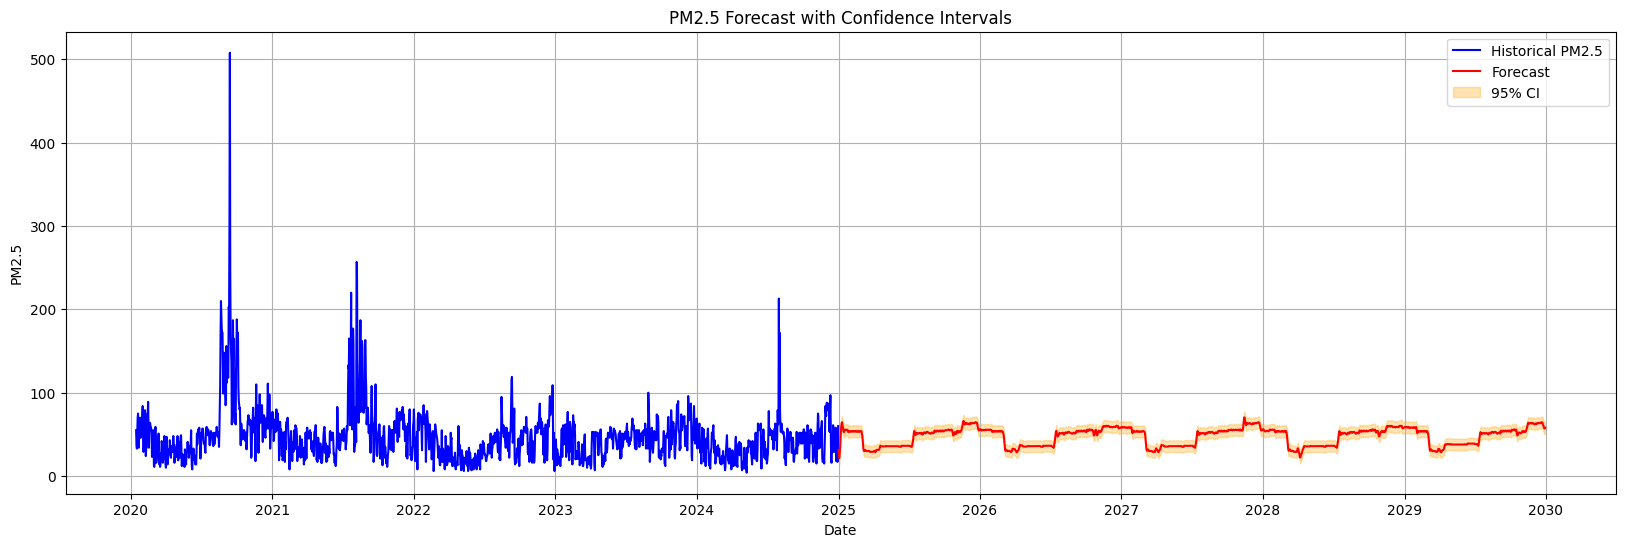

In [18]:
# Forecast plotting
plt.figure(figsize=(20,6))
plt.plot(df['Date'], df['PM25'], color='blue', label='Historical PM2.5')
plt.plot(forecast_df['Date'], forecast_df['Forecast_PM25'], color='red', label='Forecast')
plt.fill_between(forecast_df['Date'], forecast_df['Lower_Bound'], forecast_df['Upper_Bound'], color='orange', alpha=0.3, label='95% CI')
plt.xlabel("Date")
plt.ylabel("PM2.5")
plt.title("PM2.5 Forecast with Confidence Intervals")
plt.legend()
plt.grid(True)
plt.show()

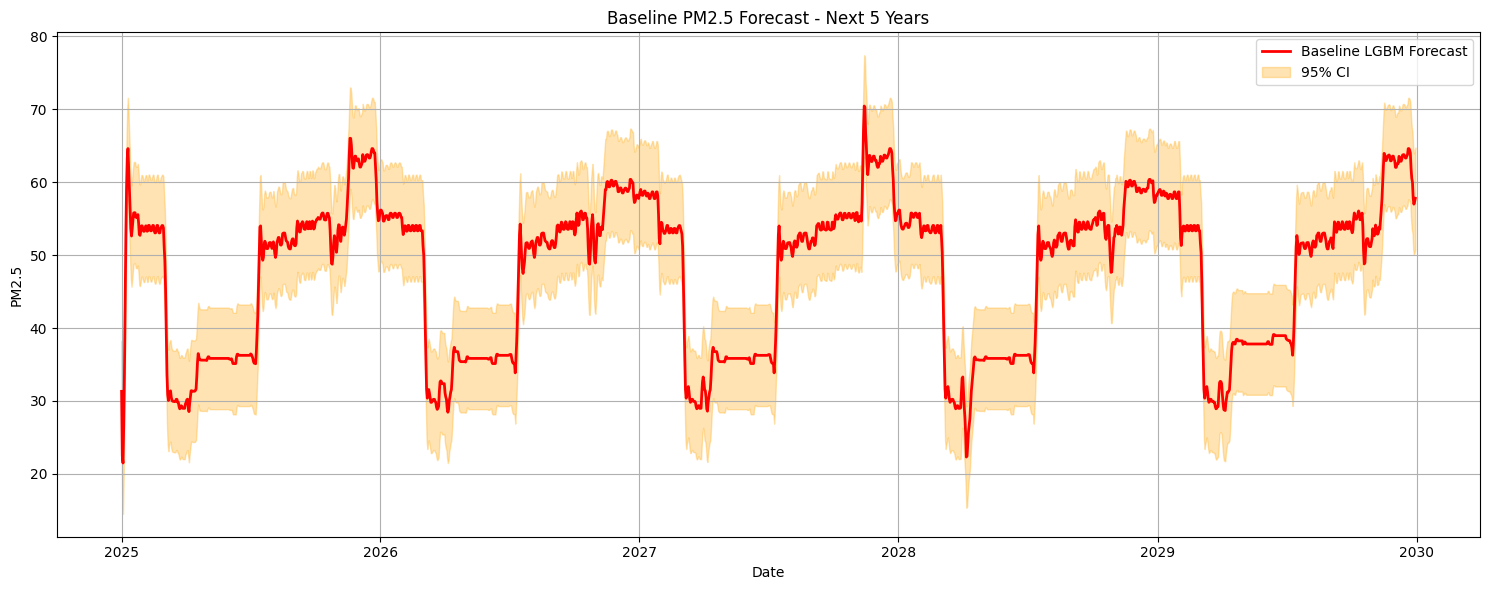

In [17]:
plt.figure(figsize=(15,6))

# Baseline model forecast curve
plt.plot(
    forecast_df['Date'],
    forecast_df['Forecast_PM25'],
    color='red',
    label='Baseline LGBM Forecast',
    linewidth=2
)

# Confidence interval shading
plt.fill_between(
    forecast_df['Date'],
    forecast_df['Lower_Bound'],
    forecast_df['Upper_Bound'],
    color='orange',
    alpha=0.3,
    label='95% CI'
)

plt.xlabel("Date")
plt.ylabel("PM2.5")
plt.title("Baseline PM2.5 Forecast - Next 5 Years")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()